### 加载数据

In [1]:
import polars as pl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from skfolio import Population,MultiPeriodPortfolio
from skfolio import RiskMeasure, PerfMeasure, RatioMeasure
from skfolio.datasets import load_sp500_dataset
from skfolio.preprocessing import prices_to_returns
from ml4t.data.providers.qmt_provider import QmtProvider
from sklearn import set_config
from log_result import init_logger, log_result, log_print
from synthetic_returns import estimate_marginal_stats, synthesize_returns
set_config(transform_output="pandas")
init_logger("CSCV_252")      # 只调用一次, 绑定文件名
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False   # 关键: 负号才不会变方块

[log] 已绑定: D:\machine-learning-for-trading\case_studies\lazy_trading\logs\CSCV_252.log


In [2]:
# 加载数据
prices = pl.read_parquet("hs_funds_prices.parquet").to_pandas()
prices = prices.set_index('timestamp')
prices = prices.ffill()
prices = prices[prices.index.year > 2019]
#prices = prices[prices.index.year < 2017]
all_symbols = prices.columns
log_print(f"测试资产池: {len(all_symbols)} 只 | {len(prices)} 天 | {prices.index[0].date()} ~ {prices.index[-1].date()}",section="资产池", echo=True)

# 市场基准（从资产池中取出）
bench_symbols = ["510880.SH","510300.SH"]
benchs = [prices[bench_symbol] for bench_symbol in bench_symbols]
#prices = prices.drop(columns=bench_symbols)

# 双口径收益率: X=绝对收益, X_net=超额收益(减基准), 筛选与训练统一用X_net
X = prices_to_returns(prices, drop_inceptions_nan=False)
bench_rets = [prices_to_returns(bench.to_frame("bench"), drop_inceptions_nan=False)["bench"] for bench in benchs]
X_net = X.sub(bench_rets[1], axis=0)

# Inf 检查（两口径分别报告）
for label, df in [("X", X), ("X_net", X_net)]:
    inf = df.columns[np.isinf(df).any(axis=0)]
    print(f"{label} Inf列 {len(inf)}" + (f" -> {inf.tolist()}" if len(inf) else ""))

# 异常收益检查: 以超额口径判定, 同步剔除, 保证两口径列集一致
bad = X_net.columns[(X_net.abs() > 0.25).any()]
X = X.drop(columns=bad)
X_net = X_net.drop(columns=bad)
msg = f"异常剔除(±25%): {len(bad)} 列 -> {bad.tolist()}" if len(bad) else "异常剔除(±25%): 0 列"
print(msg)
print(f"清洗后: {X.shape[0]} 天 x {X.shape[1]} 资产 | 列集一致: {list(X.columns) == list(X_net.columns)}")

测试资产池: 2141 只 | 1629 天 | 2020-01-02 ~ 2026-09-18
X Inf列 0
X_net Inf列 0
异常剔除(±25%): 3 列 -> ['161811.SZ', '510030.SH', '511580.SH']
清洗后: 1628 天 x 2138 资产 | 列集一致: True


In [3]:
prices = prices.iloc[1:,:]

In [4]:
#stats  = estimate_marginal_stats(X)                        # ① 逐标的统计属性 + 拟合参数表
#X_fake = synthesize_returns(X, random_state=42)            # ② 默认 student_t + 保留截面相关
#X_fake, report = synthesize_returns(X, random_state=42, return_report=True)
X_ctrl = synthesize_returns(X, distribution="gaussian")    # 高斯对照项
X_fake = synthesize_returns(X, random_state=42)

硬截断告警：2 列截断比例超过阈值（最高 159083.SZ: 截断 11.54% / 阈值 22.22% / 样本 26）
硬截断告警：8 列截断比例超过阈值（最高 512420.SH: 截断 13.33% / 阈值 19.35% / 样本 30）


In [6]:
from cpcv_search_base import build_pipeline_src
from cpcv_analysis import plot_oos_vs_bench
from sl_simulation import load_sl_config, simulate_sl, summarize_sl, simulate_fixed, simulate_wf

### Fixed Simulate

In [7]:
from skfolio import Population

### TopK best parameters

In [ ]:
# CSCV评估区：2012-02-07 ~ 2020-05-20 
topk_params = [{'nondomin__min_n_assets': 55, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.1, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 35, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.5, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 75, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.1, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 75, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.1, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sortino-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 35, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.3, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 15, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.5, 'extremes__k': 0.7, 'nondomin__fitness_measures': 'sortino-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 75, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.3, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'mean-mad-maxdd-kurt', 'train_size': 504}
,{'nondomin__min_n_assets': 35, 'nondomin__threshold': -0.3, 'correlate__threshold': 0.5, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 35, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.3, 'extremes__k': 0.5, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 95, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.1, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sortino-maxdd-kurt', 'train_size': 252}
]

In [ ]:
# CSCV评估区：2013-01-30 ~ 2021-05-19
topk_params = [{'nondomin__min_n_assets': 35, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.5, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 35, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.5, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sortino-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 75, 'nondomin__threshold': -0.3, 'correlate__threshold': 0.1, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 75, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.1, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 95, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.1, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sortino-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 15, 'nondomin__threshold': -0.3, 'correlate__threshold': 0.1, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 504}
,{'nondomin__min_n_assets': 15, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.1, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 504}
,{'nondomin__min_n_assets': 95, 'nondomin__threshold': -0.3, 'correlate__threshold': 0.5, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 75, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.1, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sortino-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 35, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.7, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 252}]

In [59]:
# CSCV评估区：2014-02-12 ~ 2022-05-23
topk_params = [{'nondomin__min_n_assets': 75, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.1, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sortino-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 15, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.1, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sortino-maxdd-kurt', 'train_size': 504}
,{'nondomin__min_n_assets': 15, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.3, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'mean-mad-maxdd-kurt', 'train_size': 504}
,{'nondomin__min_n_assets': 95, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.1, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'mean-mad-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 75, 'nondomin__threshold': -0.3, 'correlate__threshold': 0.1, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sortino-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 15, 'nondomin__threshold': -0.3, 'correlate__threshold': 0.1, 'extremes__k': 0.7, 'nondomin__fitness_measures': 'sortino-maxdd-kurt', 'train_size': 504}
,{'nondomin__min_n_assets': 15, 'nondomin__threshold': -0.3, 'correlate__threshold': 0.3, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'mean-semideviation-maxdd-kurt', 'train_size': 504}
,{'nondomin__min_n_assets': 75, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.1, 'extremes__k': 0.7, 'nondomin__fitness_measures': 'sortino-maxdd-kurt', 'train_size': 504}
,{'nondomin__min_n_assets': 55, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.1, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'mean-mad-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 75, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.1, 'extremes__k': 0.7, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 504}]

In [78]:
# CSCV评估区：2015-02-04 ~ 2023-05-22
topk_params = [{'nondomin__min_n_assets': 75, 'nondomin__threshold': -0.3, 'correlate__threshold': 0.1, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 35, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.1, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sortino-maxdd-kurt', 'train_size': 504}
,{'nondomin__min_n_assets': 15, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.3, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'mean-mad-maxdd-kurt', 'train_size': 504}
,{'nondomin__min_n_assets': 15, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.3, 'extremes__k': 0.7, 'nondomin__fitness_measures': 'mean-variance-maxdd-kurt', 'train_size': 504}
,{'nondomin__min_n_assets': 15, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.1, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 504}
,{'nondomin__min_n_assets': 95, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.3, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 15, 'nondomin__threshold': -0.3, 'correlate__threshold': 0.3, 'extremes__k': 0.7, 'nondomin__fitness_measures': 'mean-variance-maxdd-kurt', 'train_size': 504}
,{'nondomin__min_n_assets': 35, 'nondomin__threshold': -0.3, 'correlate__threshold': 0.1, 'extremes__k': 0.7, 'nondomin__fitness_measures': 'mean-semideviation-maxdd-kurt', 'train_size': 504}
,{'nondomin__min_n_assets': 55, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.1, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 75, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.1, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sortino-maxdd-kurt', 'train_size': 504}]

In [97]:
# CSCV评估区：2016-01-26 ~ 2024-05-16 
topk_params = [{'nondomin__min_n_assets': 75, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.1, 'extremes__k': 0.7, 'nondomin__fitness_measures': 'mean-semideviation-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 75, 'nondomin__threshold': -0.3, 'correlate__threshold': 0.3, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'mean-variance-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 35, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.3, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 55, 'nondomin__threshold': -0.3, 'correlate__threshold': 0.1, 'extremes__k': 0.7, 'nondomin__fitness_measures': 'mean-variance-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 95, 'nondomin__threshold': -0.3, 'correlate__threshold': 0.3, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'mean-semideviation-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 55, 'nondomin__threshold': -0.3, 'correlate__threshold': 0.1, 'extremes__k': 0.7, 'nondomin__fitness_measures': 'mean-mad-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 95, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.1, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'mean-mad-maxdd-kurt', 'train_size': 504}
,{'nondomin__min_n_assets': 95, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.3, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sortino-maxdd-kurt', 'train_size': 504}
,{'nondomin__min_n_assets': 95, 'nondomin__threshold': -0.3, 'correlate__threshold': 0.3, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'mean-variance-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 95, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.1, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 504}]

In [117]:
# CSCV评估区：2017-01-26 ~ 2025-05-21 
topk_params = [{'nondomin__min_n_assets': 95, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.1, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 95, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.1, 'extremes__k': 0.7, 'nondomin__fitness_measures': 'mean-mad-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 95, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.3, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'mean-semideviation-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 95, 'nondomin__threshold': -0.5, 'correlate__threshold': 0.1, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'mean-mad-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 95, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.1, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 504}
,{'nondomin__min_n_assets': 75, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.1, 'extremes__k': 0.7, 'nondomin__fitness_measures': 'mean-mad-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 95, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.1, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'mean-mad-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 95, 'nondomin__threshold': -0.3, 'correlate__threshold': 0.1, 'extremes__k': 0.7, 'nondomin__fitness_measures': 'sortino-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 95, 'nondomin__threshold': -0.3, 'correlate__threshold': 0.1, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 504}
,{'nondomin__min_n_assets': 75, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.1, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'mean-semideviation-maxdd-kurt', 'train_size': 252}]

In [136]:
# # CSCV评估区：2012-02-07 ~ 2022-06-17
topk_params = [{'nondomin__min_n_assets': 35, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.5, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 35, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.3, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 15, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.1, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'mean-mad-maxdd-kurt', 'train_size': 504}
,{'nondomin__min_n_assets': 75, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.3, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sortino-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 75, 'nondomin__threshold': -0.5, 'correlate__threshold': 0.5, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'mean-variance-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 35, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.1, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sortino-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 35, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.3, 'extremes__k': 0.5, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 75, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.5, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'mean-variance-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 35, 'nondomin__threshold': -0.5, 'correlate__threshold': 0.3, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sharpe-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 75, 'nondomin__threshold': -0.3, 'correlate__threshold': 0.3, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'sortino-maxdd-kurt', 'train_size': 252}]

In [8]:
topk_params = [{'nondomin__min_n_assets': 100, 'nondomin__threshold': -0.3, 'correlate__threshold': 0.9, 'trend__pct_to_keep': 0.1, 'trend__trend_length': 252, 'nondomin__fitness_measures': 'mean-variance-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 100, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.5, 'trend__pct_to_keep': 0.3, 'trend__trend_length': 252, 'nondomin__fitness_measures': 'mean-variance-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 130, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.7, 'trend__pct_to_keep': 0.1, 'trend__trend_length': 252, 'nondomin__fitness_measures': 'mean-variance-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 150, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.7, 'trend__pct_to_keep': 0.1, 'trend__trend_length': 252, 'nondomin__fitness_measures': 'mean-variance-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 100, 'nondomin__threshold': -0.3, 'correlate__threshold': 0.7, 'trend__pct_to_keep': 0.3, 'trend__trend_length': 252, 'nondomin__fitness_measures': 'mean-variance-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 150, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.5, 'trend__pct_to_keep': 0.1, 'trend__trend_length': 252, 'nondomin__fitness_measures': 'mean-variance-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 100, 'nondomin__threshold': -0.3, 'correlate__threshold': 0.5, 'trend__pct_to_keep': 0.3, 'trend__trend_length': 252, 'nondomin__fitness_measures': 'mean-variance-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 120, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.7, 'trend__pct_to_keep': 0.3, 'trend__trend_length': 252, 'nondomin__fitness_measures': 'mean-variance-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 100, 'nondomin__threshold': -0.9, 'correlate__threshold': 0.9, 'trend__pct_to_keep': 0.1, 'trend__trend_length': 252, 'nondomin__fitness_measures': 'mean-variance-maxdd-kurt', 'train_size': 252}
,{'nondomin__min_n_assets': 100, 'nondomin__threshold': -0.3, 'correlate__threshold': 0.5, 'trend__pct_to_keep': 0.9, 'trend__trend_length': 252, 'nondomin__fitness_measures': 'mean-variance-maxdd-kurt', 'train_size': 252}]

In [10]:
topk_res = [simulate_wf(X, prices=prices, params=best_param, test_size=252) for best_param in topk_params]

Fold 0: 2021-01-18 -> 2022-01-28 (252d, expired) | wf | ASR=-0.467 | 累计=-6.49%
Fold 1: 2022-02-07 -> 2023-02-17 (252d, expired) | wf | ASR=0.076 | 累计=0.14%
Fold 2: 2023-02-20 -> 2024-03-04 (252d, expired) | wf | ASR=0.080 | 累计=0.22%
Fold 3: 2024-03-05 -> 2025-03-19 (252d, expired) | wf | ASR=2.567 | 累计=3.65%
Fold 4: 2025-03-20 -> 2026-04-02 (252d, expired) | wf | ASR=1.364 | 累计=7.18%
Fold 5: 2026-04-03 -> 2026-09-18 (116d, end_of_data) | wf | ASR=0.502 | 累计=3.46%
Fold 0: 2021-01-18 -> 2022-01-28 (252d, expired) | wf | ASR=0.040 | 累计=-0.14%
Fold 1: 2022-02-07 -> 2023-02-17 (252d, expired) | wf | ASR=0.109 | 累计=0.24%
Fold 2: 2023-02-20 -> 2024-03-04 (252d, expired) | wf | ASR=0.567 | 累计=2.03%
Fold 3: 2024-03-05 -> 2025-03-19 (252d, expired) | wf | ASR=1.584 | 累计=4.49%
Fold 4: 2025-03-20 -> 2026-04-02 (252d, expired) | wf | ASR=0.677 | 累计=3.14%
Fold 5: 2026-04-03 -> 2026-09-18 (116d, end_of_data) | wf | ASR=1.032 | 累计=5.59%
Fold 0: 2021-01-18 -> 2022-01-28 (252d, expired) | wf | ASR=-0.03

In [11]:
for i,res in enumerate(topk_res):
    res['mpt'].name = f'top-{i+1}'

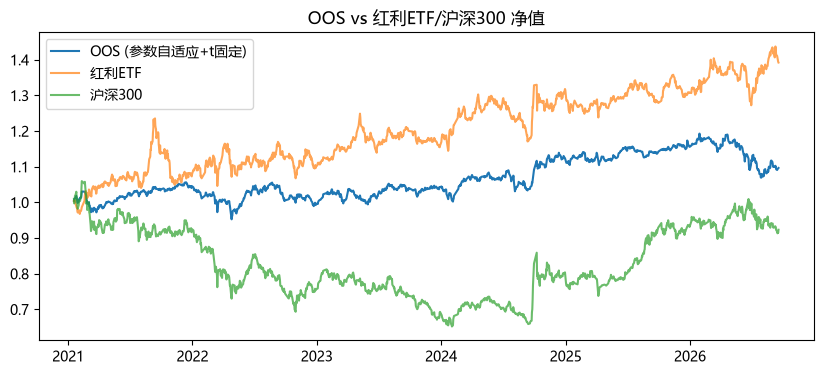

In [139]:
# 252
plot_oos_vs_bench(topk_res[0]['mpt'], bench_rets, bench_labels=['红利ETF','沪深300'])

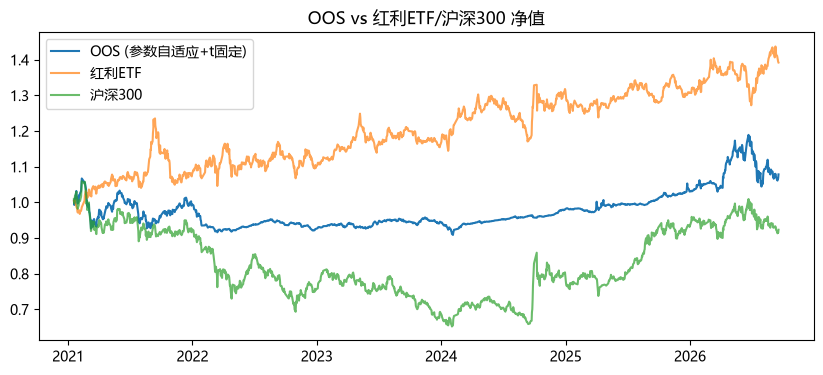

In [12]:
plot_oos_vs_bench(topk_res[0]['mpt'], bench_rets, bench_labels=['红利ETF','沪深300'])

In [13]:
topk_pops = Population([res['mpt'] for res in topk_res])

In [14]:
topk_pops.plot_cumulative_returns()

In [15]:
topk_pops.plot_drawdowns()

In [16]:
topk_pops.plot_returns_distribution()

In [17]:
oos_summary = topk_pops.summary()
oos_summary = oos_summary.loc[['Annualized Mean','Annualized Variance','MAX Drawdown','CVaR at 95%','Kurtosis','Skew',
                 'Annualized Sharpe Ratio','Annualized Sortino Ratio','Calmar Ratio',
                 'Avg nb of Assets per Portfolio','Number of Portfolios']]
print(oos_summary.to_string())

                                   top-1    top-2     top-3     top-4     top-5     top-6    top-7     top-8     top-9   top-10
Annualized Mean                    1.71%    2.96%     2.67%     2.48%     4.10%     5.75%    3.86%     3.46%     0.66%    4.70%
Annualized Variance                0.64%    0.43%     0.45%     0.49%     0.49%     0.79%    0.64%     0.53%     0.50%    0.51%
MAX Drawdown                      14.83%   12.10%    12.54%    12.54%    13.58%    18.83%   12.79%    13.16%    15.03%   11.53%
CVaR at 95%                        1.38%    1.07%     1.14%     1.17%     1.19%     1.42%    1.32%     1.22%     1.23%    1.06%
Kurtosis                        1129.15%  868.63%  1212.38%  1045.77%  1002.66%  1396.90%  904.94%  1025.63%  1157.25%  874.19%
Skew                             -36.01%  -21.78%     6.15%     4.89%   -31.03%    34.08%   -8.13%   -37.50%   -43.51%  -36.11%
Annualized Sharpe Ratio             0.21     0.45      0.40      0.36      0.58      0.65     0.48      

In [144]:
log_print(oos_summary.to_string(), section="样本外测试(252天/更新频率)", echo=True)

                                  top-1    top-2     top-3    top-4    top-5     top-6     top-7    top-8    top-9   top-10
Annualized Mean                   1.93%    2.77%     9.58%    2.30%    2.09%     5.43%     2.74%    2.09%    2.77%    2.23%
Annualized Variance               0.48%    0.54%     0.77%    0.26%    0.36%     0.65%     0.69%    0.36%    0.54%    0.35%
MAX Drawdown                     10.33%    8.66%     8.40%    6.42%   10.23%     8.87%     9.95%   10.23%    8.66%    9.67%
CVaR at 95%                       1.00%    1.09%     1.21%    0.73%    0.91%     1.20%     1.24%    0.91%    1.09%    0.85%
Kurtosis                        698.12%  773.73%  1171.72%  700.44%  638.37%  1026.66%  1029.08%  638.37%  773.73%  938.54%
Skew                            -19.45%  -24.48%    19.83%    0.86%  -34.68%   -48.68%   -52.29%  -34.68%  -24.48%  -13.96%
Annualized Sharpe Ratio            0.28     0.38      1.09     0.46     0.35      0.68      0.33     0.35     0.38     0.38
Annualiz

In [150]:
log_print(oos_summary.to_string(), section="样本外测试(126天/更新频率)", echo=True)

                                  top-1    top-2     top-3    top-4    top-5     top-6     top-7    top-8    top-9   top-10
Annualized Mean                   2.87%    4.38%     4.82%    3.60%    3.66%     7.44%     4.64%    3.66%    4.52%    2.90%
Annualized Variance               0.42%    0.48%     0.53%    0.29%    0.39%     0.67%     0.66%    0.39%    0.48%    0.40%
MAX Drawdown                     10.12%    8.05%     8.05%    7.12%    7.32%     7.42%     9.51%    7.32%    8.05%    9.67%
CVaR at 95%                       0.96%    1.03%     1.10%    0.78%    0.94%     1.17%     1.19%    0.94%    1.03%    0.91%
Kurtosis                        836.87%  897.04%  1149.54%  720.51%  676.92%  1407.54%  1107.28%  676.92%  905.68%  836.12%
Skew                            -34.05%  -29.38%   -60.07%  -10.15%  -46.65%    15.59%   -55.08%  -46.65%  -29.64%  -17.79%
Annualized Sharpe Ratio            0.44     0.63      0.66     0.67     0.58      0.91      0.57     0.58     0.65     0.46
Annualiz